In [ ]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [ ]:
#Amitava Chakraborty - 05th Jan 2018
#Overview of working with Qiskit

#The fundamental unit of Qiskit is Quantum Circuit. 
#A workflow using Qiskit has two stages: 
#1)Build - make the quantum circuits that represent the problem
#2)Execute - run them on different backends
#After the jobs are run, the data is collected. 

# Importing standard Qiskit libraries and configuring account
import numpy as np
from qiskit import QuantumRegister, QuantumCircuit
from qiskit_backend_config import execute, Aer
from qiskit.visualization import plot_histogram

In [ ]:
#We create a Quantum Register with 3 qubits.
q = QuantumRegister(3, 'q')
#Note: Naming the QuantumRegister is optional and not required.

# Create a Quantum Circuit acting on the q register
circ = QuantumCircuit(q)

In [ ]:
#An example of a quantum circuit that makes a three-qubit GHZ state
#To create such a state, we start with a 3-qubit quantum register. 
#By default, each qubit in the register is initialized to $|0\rangle$. 
#To make the GHZ state, we apply the following gates:

#A Hadamard gate $H$ on qubit 0, which puts it into a superposition state.
#A controlled-Not operation ($C_{X}$) between qubit 0 and qubit 1.
#A controlled-Not operation between qubit 0 and qubit 2.
#On an ideal quantum computer, the state produced by running this circuit would be the GHZ state

#In Qiskit, operations can be added to the circuit one-by-one
circ = QuantumCircuit(3,3)
# Add a H gate on qubit 0, putting this qubit in superposition.
circ.h(q[0])
# Add a CX (CNOT) gate on control qubit 0 and target qubit 1, putting
# the qubits in a Bell state.
circ.cx(q[0], q[1])
# Add a CX (CNOT) gate on control qubit 0 and target qubit 2, putting
# the qubits in a GHZ state.
circ.cx(q[1], q[2])

# Map the quantum measurement to the classical bits
#measure(qubit, cbit) - first is qbit array, second is cbit array
circ.measure([0,1,2],[0,1,2])

#Visualize Circuit
#We use Qiskit QuantumCircuit.draw()
circ.draw()

#Setup matplotlib as default in '~/.qiskit/settings.conf'
#circuit_drawer = mpl
#Or for full latex experience, use circuit_drawer = latex

┌───┐          ┌─┐      
q_0: ┤ H ├──■───────┤M├──────
     └───┘┌─┴─┐     └╥┘┌─┐   
q_1: ─────┤ X ├──■───╫─┤M├───
          └───┘┌─┴─┐ ║ └╥┘┌─┐
q_2: ──────────┤ X ├─╫──╫─┤M├
               └───┘ ║  ║ └╥┘
c: 3/════════════════╩══╩══╩═
                     0  1  2


Total count for 000 and 111 are: {'111': 504, '000': 496}


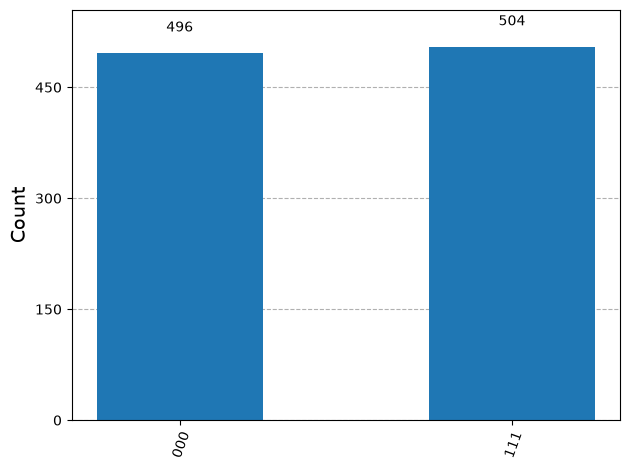

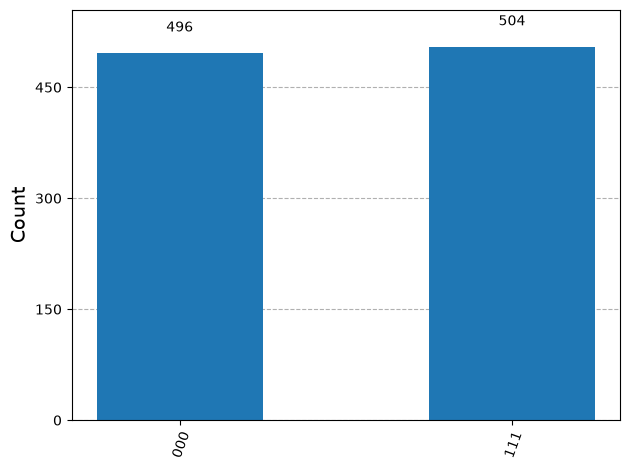

In [5]:
# Use Aer's qasm_simulator - this is not a device simulator
simulator = Aer.get_backend('qasm_simulator')

# Execute the circuit on the qasm simulator
job = execute(circ, simulator, shots=1000)
#Qiskit Aer is a high performance simulator framework for quantum circuits. 
#It provides several backends to achieve different simulation goals.
#Each run of this circuit will yield either the bit string 00 or 11.

# Grab results from the job
result = job.result()

#With the result object, we can access the counts via the method get_counts(circuit)
#returns the aggregate outcomes of the experiment
counts = result.get_counts(circ)
print("\nTotal count for 000 and 111 are:",counts)
#As expected, the output bit string is 00 approximately 50 percent of the time. 
#The number of times the circuit is run can be specified via 
#the shots argument of the execute method. 
# Plot a histogram
plot_histogram(counts)

In [6]:
#Simulating circuits using Qiskit Aer 
# Import Aer
from qiskit_backend_config import BasicAer

#Qiskit Aer provides many different backends for simulation
#Here we use the basic python version - Statevector backend - the most common backend in Qiskit Aer.

#To run the above circuit using the statevector simulator, set the backend to statevector_simulator.
backend = BasicAer.get_backend('statevector_simulator')

#This simulator returns the quantum state which is 
#a complex vector of dimensions 2^n for n qubits 

#When representing the state of a multi-qubit system, 
#the tensor order used in qiskit is different than that used in most physics textbooks. 
#For n qubits, qubit j is labeled as Q_{j}. 
#Qiskit uses an ordering in which the n^{\mathrm{th}} qubit is on the left side of the tensor product, 
#so that the basis vectors are labeled as  Q_n tensor_cross Q_(n-1) tensor_cross .. Q_0. 
#For example, if qubit zero is in state 0, qubit 1 is in state 0, and qubit 2 is in state 1, 
#qiskit would represent this state as |100> 
#whereas many physics textbooks would represent it as |001>
#This difference in labeling affects the way multi-qubit operations are represented as matrices. 
#For example, qiskit represents a controlled-X (CX) operation with 
#qubit 0 being the control and qubit 1 being the target 
#as CX = [[1,0,0,0], [0,0,0,1], [0,0,1,0], [0,1,0,0]]

#Now we compile and run the quantum circuit - the execute function
#it returns a job object that encapsulates information about the job submitted to the backend.
#In Jupyter - Simply place the text cursor on a function and press Shift+Tab.

# Create a Quantum Program for execution 
job = execute(circ, backend)

C:\Users\AMITAVA\AppData\Local\Temp\ipykernel_60944\1452335014.py:9: DeprecationWarning: BasicAer is removed in Qiskit 2.x.  Using AerSimulator as a drop-in replacement.
  backend = BasicAer.get_backend('statevector_simulator')


Statevector([1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j],
            dims=(2, 2, 2))


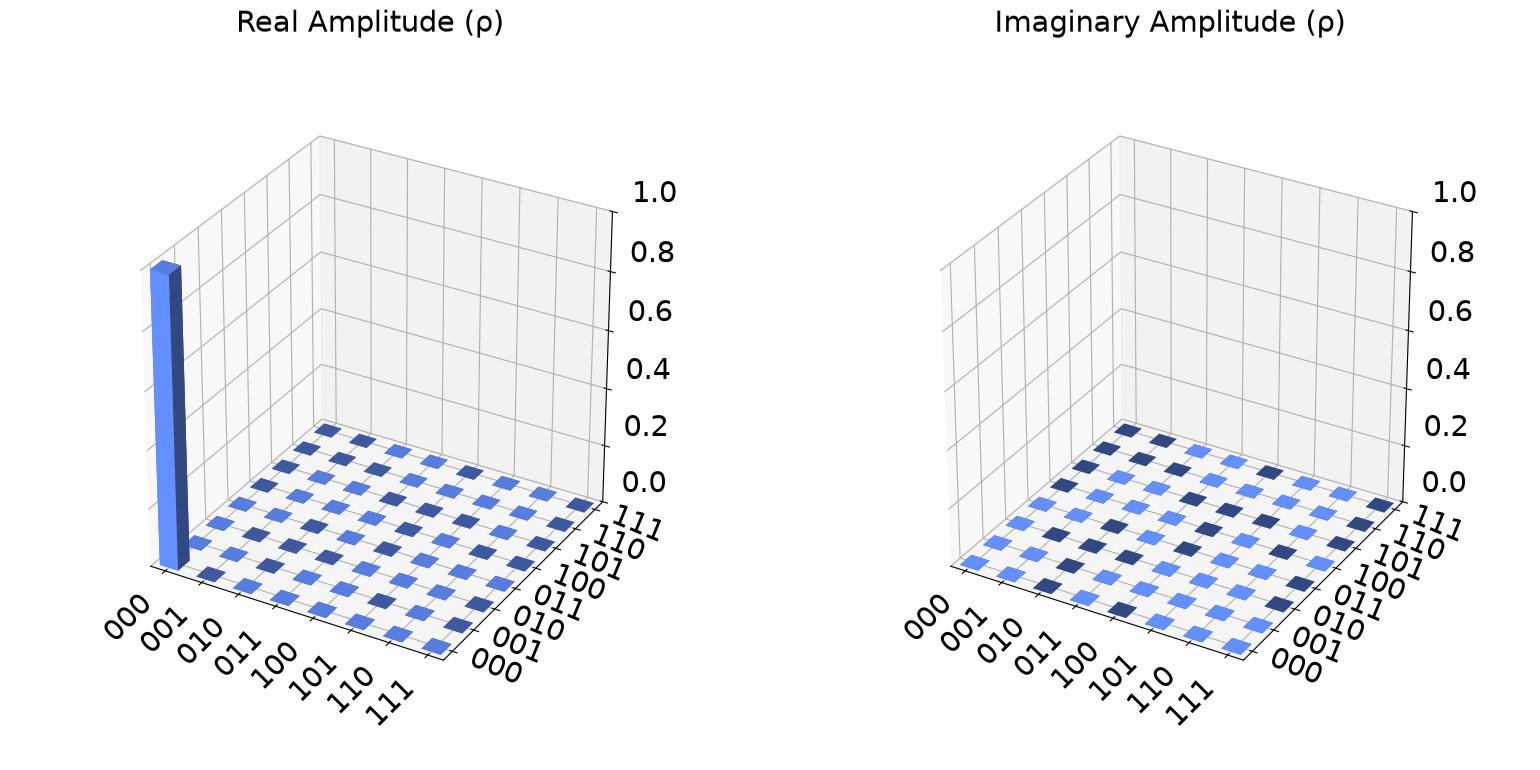

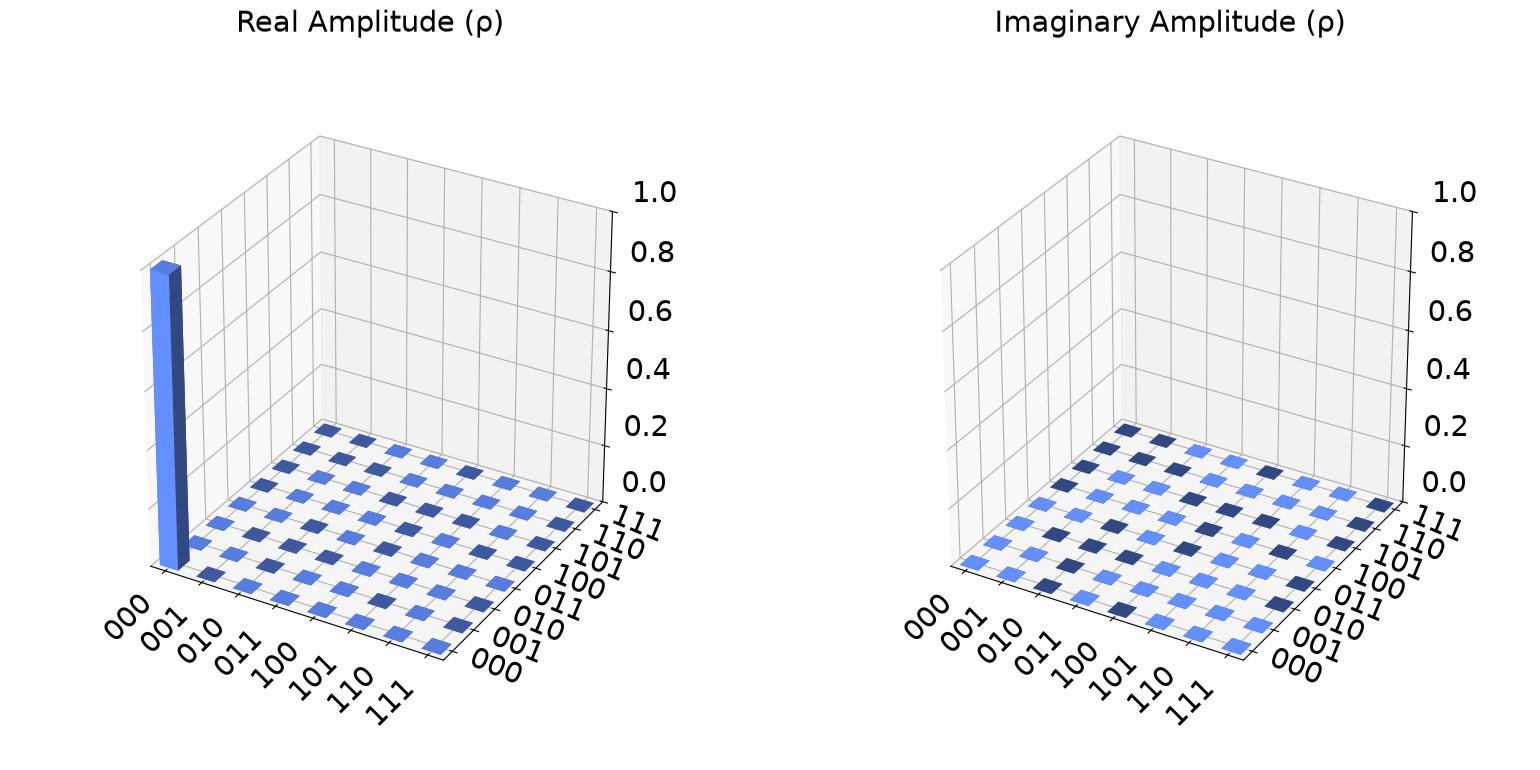

In [7]:
#The job object has 
#job.status() and 
#job.result()

#Note: Jobs run asynchronously but when the result method is called it switches to synchronous and 
#waits for it to finish before moving on to another task.
result = job.result()

#The results object contains the data and 
#result.get_statevector(circ) - returns the state vector for the quantum circuit.
outputstate = result.get_statevector(circ, decimals=3)
print(outputstate)

#Qiskit also provides a visualization toolbox to allow you to view these results.
#Use visualization function to plot the real and imaginary components of the state vector.
from qiskit.visualization import plot_state_city
plot_state_city(outputstate)

In [8]:
#Unitary backend
#Qiskit Aer also includes a unitary_simulator 
#that works provided all the elements in the circuit are unitary operations. 
#This backend calculates the 2^n X 2^n matrix representing the gates in the quantum circuit.

# Run the quantum circuit on a unitary simulator backend
backend = BasicAer.get_backend('unitary_simulator')
job = execute(circ, backend)
result = job.result()

# Show the results
print(result.get_unitary(circ, decimals=3))

Operator([[ 0.707+0.j,  0.707-0.j,  0.   +0.j,  0.   +0.j,  0.   +0.j,
            0.   +0.j,  0.   +0.j,  0.   +0.j],
          [ 0.   +0.j,  0.   +0.j,  0.707+0.j, -0.707+0.j,  0.   +0.j,
            0.   +0.j,  0.   +0.j,  0.   +0.j],
          [ 0.   +0.j,  0.   +0.j,  0.   +0.j,  0.   +0.j,  0.   +0.j,
            0.   +0.j,  0.707+0.j,  0.707-0.j],
          [ 0.   +0.j,  0.   +0.j,  0.   +0.j,  0.   +0.j,  0.707+0.j,
           -0.707+0.j,  0.   +0.j,  0.   +0.j],
          [ 0.   +0.j,  0.   +0.j,  0.   +0.j,  0.   +0.j,  0.707+0.j,
            0.707-0.j,  0.   +0.j,  0.   +0.j],
          [ 0.   +0.j,  0.   +0.j,  0.   +0.j,  0.   +0.j,  0.   +0.j,
            0.   +0.j,  0.707+0.j, -0.707+0.j],
          [ 0.   +0.j,  0.   +0.j,  0.707+0.j,  0.707-0.j,  0.   +0.j,
            0.   +0.j,  0.   +0.j,  0.   +0.j],
          [ 0.707+0.j, -0.707+0.j,  0.   +0.j,  0.   +0.j,  0.   +0.j,
            0.   +0.j,  0.   +0.j,  0.   +0.j]],
         input_dims=(2, 2, 2), output_dims=(2, 

C:\Users\AMITAVA\AppData\Local\Temp\ipykernel_60944\804816852.py:7: DeprecationWarning: BasicAer is removed in Qiskit 2.x.  Using AerSimulator as a drop-in replacement.
  backend = BasicAer.get_backend('unitary_simulator')


In [9]:
#OpenQASM backend
#The simulators above are useful because they provide information 
#about the state output by the ideal circuit and the matrix representation of the circuit. 
#However, a real experiment terminates by measuring each qubit 
#(usually in the computational $|0\rangle, |1\rangle$ basis). 
#Without measurement, we cannot gain information about the state. 
#Measurements cause the quantum system to collapse into classical bits.

#For example, suppose we make independent measurements on each qubit of the three-qubit GHZ state 
#$$|\psi\rangle = |000\rangle +|111\rangle)/\sqrt{2},$$ and 
#let $xyz$ denote the bitstring that results. 
#Recall that, under the qubit labeling used by Qiskit, 
#$x$ would correspond to the outcome on qubit 2, 
#$y$ to the outcome on qubit 1, and 
#$z$ to the outcome on qubit 0.

#Note: This representation of the bitstring puts the most significant bit (MSB) on the left, 
#and the least significant bit (LSB) on the right. 
#This is the standard ordering of binary bitstrings. 
#We order the qubits in the same way, which is why Qiskit uses a non-standard tensor product order.
#Recall the probability of obtaining outcome $xyz$ is given by 
#$$\mathrm{Pr}(xyz) = |\langle xyz | \psi \rangle |^{2}$$ and 
#as such for the GHZ state probability of obtaining 000 or 111 are both 1/2.

#To simulate a circuit that includes measurement, 
#we need to add measurements to the original circuit above, and use a different Aer backend.

# Create a Classical Register with 3 bits.
from qiskit import ClassicalRegister
c = ClassicalRegister(3, 'c')
# Create a Quantum Circuit
meas = QuantumCircuit(q, c)
#Now we add a barrier
#The gray barrier allows us to seperate parts of the circuit with a visual line
#While using optimization, a barrier stops the tools from optimizing accross the barrier. 
meas.barrier(q)
# map the quantum measurement to the classical bits
meas.measure(q,c)

# The Qiskit circuit object supports composition using
# the addition operator.
qc = combine(circ, meas)
#drawing the circuit
qc.draw()
#This circuit adds a classical register, 
#and three measurements that are used to map the outcome of qubits to the classical bits.

┌───┐          ┌─┐       ░ ┌─┐      
q_0: ┤ H ├──■───────┤M├───────░─┤M├──────
     └───┘┌─┴─┐     └╥┘┌─┐    ░ └╥┘┌─┐   
q_1: ─────┤ X ├──■───╫─┤M├────░──╫─┤M├───
          └───┘┌─┴─┐ ║ └╥┘┌─┐ ░  ║ └╥┘┌─┐
q_2: ──────────┤ X ├─╫──╫─┤M├─░──╫──╫─┤M├
               └───┘ ║  ║ └╥┘ ░  ║  ║ └╥┘
c: 3/════════════════╩══╩══╩═════╩══╩══╩═
                     0  1  2     0  1  2

C:\Users\AMITAVA\AppData\Local\Temp\ipykernel_60944\1397563790.py:10: DeprecationWarning: BasicAer is removed in Qiskit 2.x.  Using AerSimulator as a drop-in replacement.
  backend_sim = BasicAer.get_backend('qasm_simulator')


{'000': 505, '111': 519}


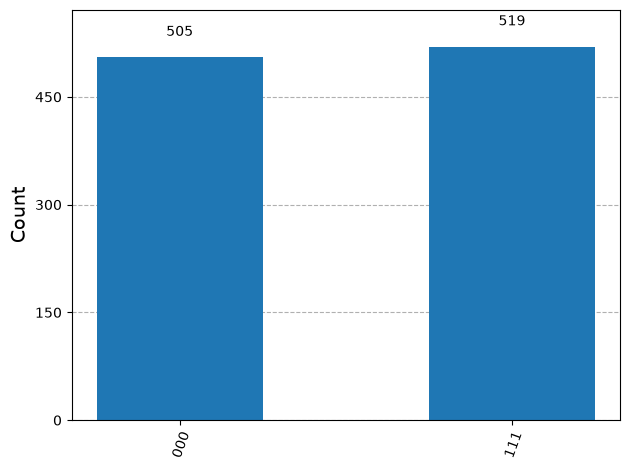

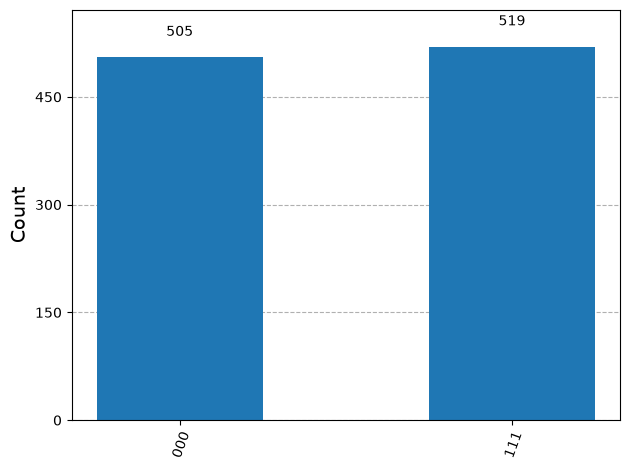

In [10]:
#To simulate this circuit, we use the qasm_simulator in Qiskit Aer. 
#Each run of this circuit will yield either the bitstring 000 or 111. 
#To build up statistics about the distribution of the bitstrings 
#(to, e.g., estimate $\mathrm{Pr}(000)$), 
#we need to repeat the circuit many times. 
#The number of times the circuit is repeated can be specified in the execute function, 
#via the shots keyword.

# Use Aer's qasm_simulator
backend_sim = BasicAer.get_backend('qasm_simulator')

# Execute the circuit on the qasm simulator.
# We've set the number of repeats of the circuit
# to be 1024, which is the default.
job_sim = execute(qc, backend_sim, shots=1024)

# Grab the results from the job.
result_sim = job_sim.result()

#In a result object, access the counts
#get_counts(circuit) - aggregated binary outcomes of the circuit submitted
counts = result_sim.get_counts(qc)
print(counts)

#Approximately 50 percent of the time the output bitstring is 000. 

#Qiskit also provides a function plot_histogram to view the outcomes
from qiskit.visualization import plot_histogram
plot_histogram(counts)

#The estimated outcome probabilities 
#$\mathrm{Pr}(000)$ and  $\mathrm{Pr}(111)$ 
#are computed by taking the aggregate counts and dividing by the number of shots 
#Try changing the shots keyword in the execute function to see how the estimated probabilities change.

In [ ]:
#Running circuits using the IBMQ provider 
#To access IBMQ devices, we need an API token. 

#IBMQ provider lets one run the circuit on real devices or on our HPC simulator. 
from qiskit_backend_config import IBMQ

#After generating your API token, 
#call: IBMQ.save_account('MY_TOKEN'). 
#This will store IBMQ credentials in a local file. 
#Unless your registration information has changed, we only need to do this once. 
#The available backends
MY_API_TOKEN='<enter-token-here>'
IBMQ.enable_account(MY_API_TOKEN)
IBMQ.save_account(MY_API_TOKEN)
#You may now load your accounts by calling,
IBMQ.load_accounts(hub=None)

#Once your account has been loaded, you can view the list of backends available to you.
print("Available backends:")
IBMQ.backends()

qiskit_runtime_service._discover_account:WARNING:2026-10-28 18:13:30,551: Loading account with the given token. A saved account will not be used.


Available backends:


h:\DevelopmentWorkspaces\gitProjects\quantumcomputing-amc\qiskit-jupyter-notebooks_dev\qiskit_backend_config.py:465: UserWarning: Could not list IBM backends ('Unable to retrieve instances. Please check that you are using a valid API token.'); using the local simulator.
  warnings.warn(f"Could not list IBM backends ({exc}); using the local simulator.")


[LegacyAerSimulator('aer_simulator')]

In [ ]:
#Running circuits on real devices
#Today's quantum information processors are small and noisy, but are advancing at a fast pace. 
#They provide a great opportunity to explore what noisy, intermediate-scale quantum (NISQ) computers can do.

#The IBMQ provider uses a queue to allocate the devices to users. 
#We now choose a device with the least busy queue which can support our program (has at least 3 qubits).
from qiskit_backend_config import least_busy

large_enough_devices = IBMQ.backends(filters=lambda x: x.configuration().n_qubits < 10 and
                                                       not x.configuration().simulator)
backend = least_busy(large_enough_devices)
print("The best backend is " + backend.name)

In [ ]:
#To run the circuit on the backend, we need to specify the number of shots and 
#the number of credits we are willing to spend to run the circuit. 
#Then, we execute the circuit on the backend using the execute function.
from qiskit_backend_config import job_monitor
shots = 1024           # Number of shots to run the program (experiment); maximum is 8192 shots.
max_credits = 3        # Maximum number of credits to spend on executions. 

job_exp = execute(qc, backend=backend, shots=shots, max_credits=max_credits)
job_monitor(job_exp)

In [ ]:
#job_exp has a .result() method 
#When the .result() method is called, the code block will wait until the job has finished 
#before releasing the cell.
result_exp = job_exp.result()
#Like before, the counts from the execution can be obtained using get_counts(qc)
counts_exp = result_exp.get_counts(qc)
plot_histogram([counts_exp,counts])

In [12]:
#Simulating circuits using a HPC simulator
#The IBMQ provider also comes with a remote optimized simulator called ibmq_qasm_simulator. 
#This remote simulator is capable of simulating up to 32 qubits. 
#It can be used the same way as the remote real backends.
simulator_backend = IBMQ.get_backend('ibmq_qasm_simulator', hub=None)
shots = 1024           # Number of shots to run the program (experiment); maximum is 8192 shots.
max_credits = 0        # Maximum number of credits to spend on executions. 
job_hpc = execute(qc, backend=simulator_backend, shots=shots, max_credits=max_credits)

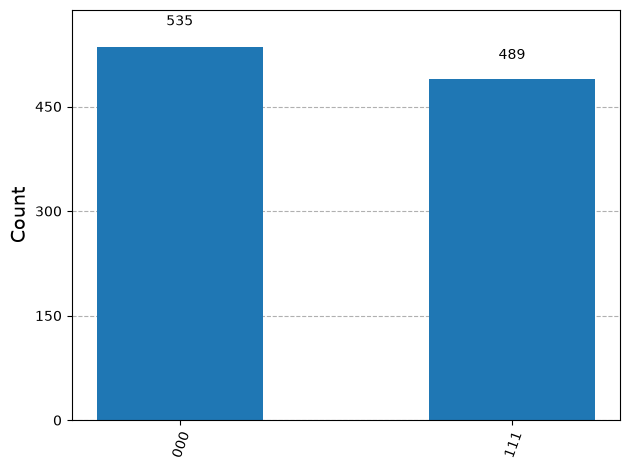

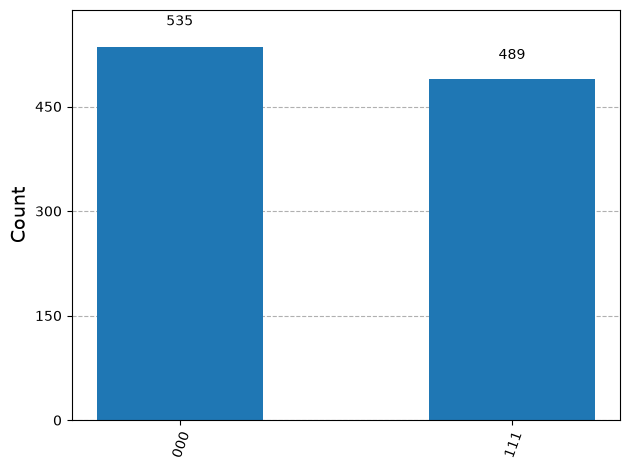

In [13]:
result_hpc = job_hpc.result()
counts_hpc = result_hpc.get_counts(qc)
plot_histogram(counts_hpc)

In [14]:
#Retrieving a previously run job
#If your experiment takes longer to run then you have time to wait around, 
#or if you simply want to retrieve old jobs back, 
#the IBMQ backends allow you to do that. 

#Note a job's ID:
jobID = job_exp.job_id()
print('JOB ID: {}'.format(jobID))

#Given a job ID, the job object can be later reconstructed from the backend using retrieve_job:
job_get=backend.retrieve_job(jobID)

#then the results can be obtained from the new job object.
job_get.result().get_counts(qc)

NameError: name 'job_exp' is not defined

In [15]:
#Choose a backend - QC - an adhoc backend
my_backend = IBMQ.get_backend('ibmq_5_tenerife', hub='ibm-q')
#my_backend = IBMQ.get_backend('ibmq_16_melbourne')
#my_backend = IBMQ.get_backend('ibmqx4')
print(my_backend)
job = execute(qc, backend=my_backend, shots=100)
print (job, job.job_id(), job.status())
result = job.result()
counts = result.get_counts()
print(counts)

qiskit_runtime_service._discover_account:WARNING:2026-10-28 18:14:46,297: Loading account with the given token. A saved account will not be used.
h:\DevelopmentWorkspaces\gitProjects\quantumcomputing-amc\qiskit-jupyter-notebooks_dev\qiskit_backend_config.py:449: UserWarning: Could not get IBM backend 'ibmq_5_tenerife' (Could not connect to IBM Quantum.  Set the IBM_QUANTUM_TOKEN environment variable or pass token= to get_backend().
Original error: 'Unable to retrieve instances. Please check that you are using a valid API token.'); using the local simulator.
  warnings.warn(f"Could not get IBM backend {name!r} ({exc}); using the local simulator.")


LegacyAerSimulator('aer_simulator')
<qiskit_backend_config.execute.<locals>._FakeJob object at 0x000002786CA6E4E0> 21252e86-98ab-4731-9fa4-974c3d7bf6a9 JobStatus.INITIALIZING
{'000': 42, '111': 58}
